#### Importing Libraries

In [4]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)



#### Loading Data

In [5]:

from pathlib import Path


RANDOM_STATE = 42

# The CSV files are stored in the data folder
DATA_DIR = Path("../data")

files = {
    "demographics": DATA_DIR / "1_patient_demographics (1).csv",
    "admissions": DATA_DIR / "2_hospital_admissions (1).csv",
    "clinical": DATA_DIR / "3_clinical_treatment (1).csv",
    "utilisation": DATA_DIR / "4_previous_utilisation.csv",
    "outcomes": DATA_DIR / "5_readmission_outcome.csv",
    "code_mapping": DATA_DIR / "6_reference_code_mapping.csv",
}


# Loading all six datasets
demographics = pd.read_csv(files["demographics"])
admissions = pd.read_csv(files["admissions"])
clinical = pd.read_csv(files["clinical"])
utilisation = pd.read_csv(files["utilisation"])
outcomes = pd.read_csv(files["outcomes"])
code_mapping = pd.read_csv(files["code_mapping"])

print("Rows and columns by source:")

for name, frame in {
    "demographics": demographics,
    "admissions": admissions,
    "clinical": clinical,
    "utilisation": utilisation,
    "outcomes": outcomes,
    "code_mapping": code_mapping
}.items():
    print(f"{name:15s}: {frame.shape}")

print("\nUnique patients:", demographics["patient_id"].nunique())
print("Unique admissions:", admissions["admission_id"].nunique())

print("\nTarget class counts:")
display(
    outcomes["readmission_within_30_days"]
    .value_counts(dropna=False)
    .rename("count")
    .to_frame()
)

target_rate = pd.to_numeric(
    outcomes["readmission_within_30_days"],
    errors="coerce"
).mean()

print(f"Observed positive-class proportion: {target_rate:.3%}")


Rows and columns by source:
demographics   : (8625, 6)
admissions     : (15446, 11)
clinical       : (15446, 21)
utilisation    : (15446, 13)
outcomes       : (15446, 8)
code_mapping   : (38, 5)

Unique patients: 8600
Unique admissions: 15400

Target class counts:


,count
readmission_within_30_days,
0,13699
1,1747


Observed positive-class proportion: 11.310%


 The extract contains six CSV files: patient demographics, hospital admissions, clinical treatment, previous utilisation, readmission outcomes, and a reference-code mapping table. The supplied documentation reports 8,625 patient records and 15,446 admission-level records in each of the admission-level tables. The modelling unit is an admission, but train/validation/test splitting is grouped by patient_id so that admissions belonging to the same patient cannot appear in more than one subset.

 The target has two classes: 0 (no readmission within 30 days) and 1 (readmission within 30 days). The data  reports an overall readmission rate of approximately 11.3%, indicating class imbalance. 
The reference mapping file is loaded for code description lookup/context; it is not used as a row-level predictor table.

#### Dataset preprocessing

In [12]:
# Standardising key strings and removing exact duplicate rows from source tables.

for frame in [
    demographics,
    admissions,
    clinical,
    utilisation,
    outcomes,
    code_mapping
]:
    # Select both traditional object columns and pandas string columns
    for col in frame.select_dtypes(include=["object", "str"]).columns:
        frame[col] = frame[col].map(
            lambda x: x.strip() if isinstance(x, str) else x
        )

demographics = demographics.drop_duplicates()
admissions = admissions.drop_duplicates()
clinical = clinical.drop_duplicates()
utilisation = utilisation.drop_duplicates()
outcomes = outcomes.drop_duplicates()
code_mapping = code_mapping.drop_duplicates()

# A modelling row should correspond to one admission in each admission-level table.
for table_name, frame in {
    "admissions": admissions, "clinical": clinical,
    "utilisation": utilisation, "outcomes": outcomes
}.items():
    if frame["admission_id"].duplicated().any():
        raise ValueError(f"{table_name} has duplicate admission_id values after exact duplicate removal.")

# Parse dates; invalid/missing timestamps become NaT and are handled conservatively.
for frame, columns in [
    (admissions, ["admission_date", "discharge_date", "prediction_timestamp"]),
    (clinical, ["lab_result_datetime"]),
    (outcomes, ["readmission_date"]),
]:
    for col in columns:
        frame[col] = pd.to_datetime(frame[col], errors="coerce")

# Join the tables. Use validated many-to-one/one-to-one joins where possible.
model_df = admissions.merge(demographics, on="patient_id", how="left", validate="many_to_one")
model_df = model_df.merge(clinical, on=["admission_id", "patient_id"], how="left", validate="one_to_one", suffixes=("", "_clinical"))
model_df = model_df.merge(utilisation, on=["admission_id", "patient_id"], how="left", validate="one_to_one", suffixes=("", "_util"))
model_df = model_df.merge(
    outcomes[["admission_id", "patient_id", "readmission_within_30_days"]],
    on=["admission_id", "patient_id"], how="left", validate="one_to_one"
)

# Exclude deceased patients per the source documentation.
deceased_mask = model_df["discharge_disposition"].astype("string").str.strip().str.lower().eq("deceased")
print("Deceased encounters excluded:", int(deceased_mask.sum()))
model_df = model_df.loc[~deceased_mask].copy()

# Require a known binary target.
model_df["readmission_within_30_days"] = pd.to_numeric(
    model_df["readmission_within_30_days"], errors="coerce"
)
model_df = model_df[model_df["readmission_within_30_days"].isin([0, 1])].copy()
model_df["readmission_within_30_days"] = model_df["readmission_within_30_days"].astype(int)

# Enforce point-in-time availability for laboratory measurements.
model_df["lab_result_datetime"] = pd.to_datetime(model_df["lab_result_datetime"], errors="coerce")
model_df["prediction_timestamp"] = pd.to_datetime(model_df["prediction_timestamp"], errors="coerce")
late_lab_mask = (
    model_df["lab_result_datetime"].notna()
    & model_df["prediction_timestamp"].notna()
    & (model_df["lab_result_datetime"] > model_df["prediction_timestamp"])
)
print("Laboratory results after prediction point excluded:", int(late_lab_mask.sum()))
model_df.loc[late_lab_mask, ["lab_result_value", "lab_test_name", "lab_test_code", "lab_result_unit", "lab_reference_range"]] = np.nan

# Feature engineering for semicolon-separated fields: keep counts, not post-discharge outcomes.
def semicolon_count(value):
    if pd.isna(value) or not str(value).strip():
        return 0
    return sum(bool(part.strip()) for part in str(value).split(";"))

for source_col, new_col in [
    ("chronic_conditions", "chronic_condition_count"),
    ("secondary_diagnosis_codes", "secondary_diagnosis_count"),
    ("procedure_codes", "procedure_code_count"),
    ("medication_names", "medication_name_count"),
    ("medication_category", "medication_category_count"),
    ("previous_admission_diagnoses", "previous_diagnosis_count"),
    ("previous_readmission_diagnoses", "previous_readmission_diagnosis_count"),
    ("previous_procedures", "previous_procedure_count"),
]:
    if source_col in model_df.columns:
        model_df[new_col] = model_df[source_col].apply(semicolon_count)

# Extract discharge-time calendar features from available admission/discharge timestamps.
model_df["admission_month"] = model_df["admission_date"].dt.month
model_df["admission_dayofweek"] = model_df["admission_date"].dt.dayofweek
model_df["discharge_month"] = model_df["discharge_date"].dt.month
model_df["discharge_dayofweek"] = model_df["discharge_date"].dt.dayofweek

# Make severity numeric if recorded as "Severity level 1" ... "Severity level 5".
model_df["clinical_severity_numeric"] = (
    model_df["clinical_severity_indicator"].astype("string")
    .str.extract(r"([1-5])", expand=False)
)
model_df["clinical_severity_numeric"] = pd.to_numeric(model_df["clinical_severity_numeric"], errors="coerce")

# Confirm target distribution after filtering.
print("Modelling rows:", len(model_df))
print("Unique patients:", model_df["patient_id"].nunique())
display(
    model_df["readmission_within_30_days"]
    .value_counts().sort_index().rename(index={0: "No readmission (0)", 1: "Readmission (1)"})
    .to_frame("count")
)
print("Positive-class proportion:", round(model_df["readmission_within_30_days"].mean(), 4))

Deceased encounters excluded: 331
Laboratory results after prediction point excluded: 2
Modelling rows: 15069
Unique patients: 6630


,count
readmission_within_30_days,
No readmission (0),13325
Readmission (1),1744


Positive-class proportion: 0.1157


preprocessing steps and why they are used
- The five patient/admission level tables are joined using their  identifiers. The reference mapping is retained for interpretation, not joined as extra rows.
- Duplicate rows are checked and removed where appropriate; join keys are checked for uniqueness to avoid accidentally multiplying admissions.
- The outcome table contributes only the target. Readmission dates, type, diagnosis and days-to-readmission are excluded because they are only known after the prediction point and would leak the answer.
- patient_id is used to create patient grouped splits but is not given to the model. This prevents the model learning patient identifiers and reduces optimistic results caused by the same patient appearing in both train and test data.
- Encounters with discharge disposition Deceased are excluded because  these patients cannot be readmitted. The target definition itself is otherwise retained as supplied; planned readmissions are not silently relabelled or removed.
- Laboratory results are retained only when lab_result_datetime is at or before the discharge prediction timestamp. Later results are treated as unavailable.
- Numeric missing values are median-imputed and categorical missing values are imputed with the most frequent category, inside a scikit-learn pipeline. This ensures imputers and encoders are fitted on training data only.
- Categorical features are one-hot encoded, with unseen categories handled safely. Existing counts are used for multi-value fields rather than creating a very large sparse vocabulary from free text.
- The data is split into 70% training, 15% validation and 15% testing by patient group. The validation set supports model selection; the test set is reserved for final unseen evaluation

#### Creating patient-grouped train, validation and test subsets
GroupShuffleSplit ensures all admissions for one patient remain in one subset. This is more appropriate than randomly splitting individual admissions because repeated encounters from one patient otherwise create leakage across subsets. The split is approximately 70/15/15.

In [14]:
# Split 15% of patients/admissions into a held-out test set, then 15% of the
# remaining rows into validation (approximately 70/15/15 overall).
X_all = model_df.drop(columns=["readmission_within_30_days"])
y_all = model_df["readmission_within_30_days"].copy()
groups = model_df["patient_id"].astype(str)

# IDs are kept separately for splitting only.
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(gss_test.split(X_all, y_all, groups=groups))

X_trainval = X_all.iloc[trainval_idx].copy()
y_trainval = y_all.iloc[trainval_idx].copy()
groups_trainval = groups.iloc[trainval_idx].copy()

# Validation is 15% of the full dataset: 0.15 / 0.85 of trainval.
gss_val = GroupShuffleSplit(n_splits=1, test_size=(0.15 / 0.85), random_state=RANDOM_STATE)
train_idx_rel, val_idx_rel = next(
    gss_val.split(X_trainval, y_trainval, groups=groups_trainval)
)

X_train = X_trainval.iloc[train_idx_rel].copy()
y_train = y_trainval.iloc[train_idx_rel].copy()
X_val = X_trainval.iloc[val_idx_rel].copy()
y_val = y_trainval.iloc[val_idx_rel].copy()
X_test = X_all.iloc[test_idx].copy()
y_test = y_all.iloc[test_idx].copy()

# Ensure patient identifiers are never predictors.
id_columns = ["patient_id", "admission_id"]
for X_part in [X_train, X_val, X_test]:
    X_part.drop(columns=[c for c in id_columns if c in X_part.columns], inplace=True)

print(f"Train:      {len(X_train):,} rows | {y_train.mean():.2%} positive")
print(f"Validation: {len(X_val):,} rows | {y_val.mean():.2%} positive")
print(f"Test:       {len(X_test):,} rows | {y_test.mean():.2%} positive")

# Verify patient separation.
patient_sets = {
    "train": set(groups.iloc[trainval_idx].iloc[train_idx_rel]),
    "validation": set(groups.iloc[trainval_idx].iloc[val_idx_rel]),
    "test": set(groups.iloc[test_idx]),
}
assert patient_sets["train"].isdisjoint(patient_sets["validation"])
assert patient_sets["train"].isdisjoint(patient_sets["test"])
assert patient_sets["validation"].isdisjoint(patient_sets["test"])
print("Patient-group separation verified.")

Train:      10,571 rows | 11.44% positive
Validation: 2,259 rows | 12.00% positive
Test:       2,239 rows | 11.79% positive
Patient-group separation verified.


#### Model training


Random Forest and hyperparameter justification
Random Forest is retained because it was the method selected in SS2. It combines many decision trees trained on bootstrapped samples and random subsets of features, helping capture non-linear relationships and interactions without requiring feature scaling.

n_estimators=300: a reasonably large ensemble to stabilise predictions; it is still practical for this dataset size.
max_depth=None: allows trees to learn complex patterns. The other controls below reduce excessive complexity.
min_samples_leaf=2: prevents leaves based on a single observation, providing modest regularisation.
max_features="sqrt": considers a random subset of features at each split, which decorrelates trees.
class_weight="balanced"  compensates for the minority readmission class during fitting. Because readmission is about 11.3% overall, accuracy alone would be misleading.
random_state=42: makes the random forest reproducible.
Optimiser / learning rate / epochs: these are not applicable to Random Forest; it is a tree-ensemble algorithm, not a gradient-trained neural network. Its main controls are the number of trees, tree depth, feature sampling and minimum leaf size.
A validation set is used to compare threshold-independent and threshold dependent metrics. The held-out test set is not used to choose the model.



In [15]:
# Exclude identifiers, raw timestamps, outcome-derived fields, and free-text fields
# that are either not appropriate as raw model inputs or would be too high-cardinality.
leakage_or_unusable = [
    "prediction_timestamp", "admission_id", "patient_id",
    "readmission_date", "readmission_type", "readmission_diagnosis_name",
    "planned_readmission_flag", "days_to_readmission",
    "readmission_within_30_days",
    "lab_result_datetime", "lab_reference_range",
    "secondary_diagnosis_names", "secondary_diagnosis_codes",
    "procedure_names", "procedure_codes", "medication_names",
    "previous_admission_diagnoses", "previous_readmission_diagnoses",
    "previous_procedures", "chronic_conditions",
    "lab_result_unit", "lab_test_code"
]

def prepare_feature_frame(frame):
    result = frame.drop(columns=[c for c in leakage_or_unusable if c in frame.columns], errors="ignore").copy()
    # Raw datetime columns are not directly modelled; calendar features were extracted above.
    for col in ["admission_date", "discharge_date", "lab_result_datetime"]:
        if col in result.columns:
            result = result.drop(columns=col)
    # Remove columns that are completely empty or constant in this particular subset.
    return result

X_train_model = prepare_feature_frame(X_train)
X_val_model = prepare_feature_frame(X_val)
X_test_model = prepare_feature_frame(X_test)

# Keep the exact same feature columns and order across subsets.
X_val_model = X_val_model.reindex(columns=X_train_model.columns)
X_test_model = X_test_model.reindex(columns=X_train_model.columns)

numeric_features = X_train_model.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train_model.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop"
)

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", rf_model)
])

model.fit(X_train_model, y_train)
print("Random Forest training complete.")
print("Training rows:", len(X_train_model))
print("Number of original input features:", X_train_model.shape[1])

Random Forest training complete.
Training rows: 10571
Number of original input features: 41


#### Validation 

The validation subset is unseen during fitting and is used to inspect performance before the final test evaluation. Because the target is imbalanced, precision, recall, F1-score and ROC-AUC are reported alongside accuracy. The default 0.50 threshold can miss the minority class, so the decision threshold is selected using validation probabilities only by maximising validation F1-score. That threshold is then frozen before the final test evaluation; the test set is not used for threshold selection.

In [16]:
from sklearn.metrics import precision_recall_curve

def metric_summary(y_true, y_pred, y_prob, subset_name):
    return {
        "subset": subset_name,
        "n": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob) if pd.Series(y_true).nunique() == 2 else np.nan,
    }

# Validation probabilities are used to select a decision threshold.
val_prob = model.predict_proba(X_val_model)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_val, val_prob)

# precision_recall_curve returns one more precision/recall point than thresholds.
candidate_f1 = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-12)
)
best_idx = int(np.nanargmax(candidate_f1))
selected_threshold = float(thresholds[best_idx])
val_pred = (val_prob >= selected_threshold).astype(int)

print(f"Validation-selected threshold (maximising F1): {selected_threshold:.4f}")
validation_metrics = metric_summary(y_val, val_pred, val_prob, "Validation")
display(pd.DataFrame([validation_metrics]).set_index("subset").round(4))
print(classification_report(y_val, val_pred, target_names=["No readmission", "Readmission"], zero_division=0))

Validation-selected threshold (maximising F1): 0.3440


,n,accuracy,precision,recall,f1,roc_auc
subset,,,,,,
Validation,2259,0.6131,0.1803,0.6273,0.2801,0.6501


                precision    recall  f1-score   support

No readmission       0.92      0.61      0.74      1988
   Readmission       0.18      0.63      0.28       271

      accuracy                           0.61      2259
     macro avg       0.55      0.62      0.51      2259
  weighted avg       0.83      0.61      0.68      2259



#### Final evaluation on the held-out test subset
The test set is evaluated only after the model has been trained and checked on validation data. These results are the final estimate of performance on unseen patients.

In [18]:

test_prob = model.predict_proba(X_test_model)[:, 1]
test_pred = (test_prob >= selected_threshold).astype(int)

test_metrics = metric_summary(y_test, test_pred, test_prob, "Test")
display(pd.DataFrame([test_metrics]).set_index("subset").round(4))
print(classification_report(y_test, test_pred, target_names=["No readmission", "Readmission"], zero_division=0))

metrics_table = pd.DataFrame([
    metric_summary(y_val, val_pred, val_prob, "Validation"),
    metric_summary(y_test, test_pred, test_prob, "Test"),
]).set_index("subset")
display(metrics_table.round(4))

,n,accuracy,precision,recall,f1,roc_auc
subset,,,,,,
Test,2239,0.5927,0.1582,0.5682,0.2475,0.6277


                precision    recall  f1-score   support

No readmission       0.91      0.60      0.72      1975
   Readmission       0.16      0.57      0.25       264

      accuracy                           0.59      2239
     macro avg       0.53      0.58      0.48      2239
  weighted avg       0.82      0.59      0.66      2239



,n,accuracy,precision,recall,f1,roc_auc
subset,,,,,,
Validation,2259,0.6131,0.1803,0.6273,0.2801,0.6501
Test,2239,0.5927,0.1582,0.5682,0.2475,0.6277


#### Results visualisation 
The following figures visualise validation and test outcomes using the decision threshold selected on validation data. The confusion matrix shows correct and incorrect classifications by class; ROC and precision-recall curves show performance across thresholds; and feature importance offers a global view of features used by the fitted forest. Feature importance is descriptive, not causal, and one-hot encoded categories may appear as separate transformed features.

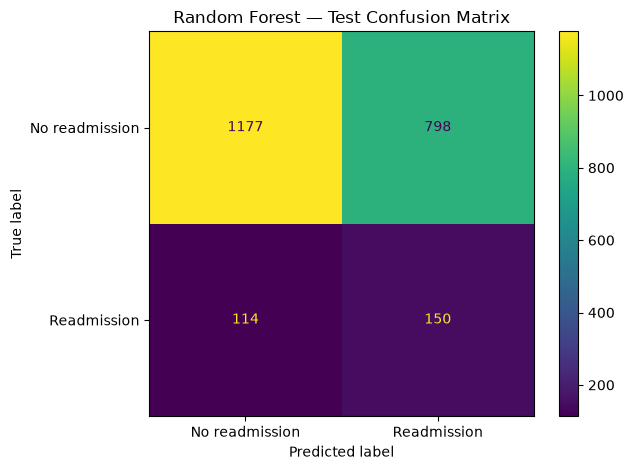

In [19]:
# Confusion matrix for the held-out test set.
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No readmission", "Readmission"]
)
disp.plot(values_format="d")
plt.title("Random Forest — Test Confusion Matrix")
plt.tight_layout()
plt.show()

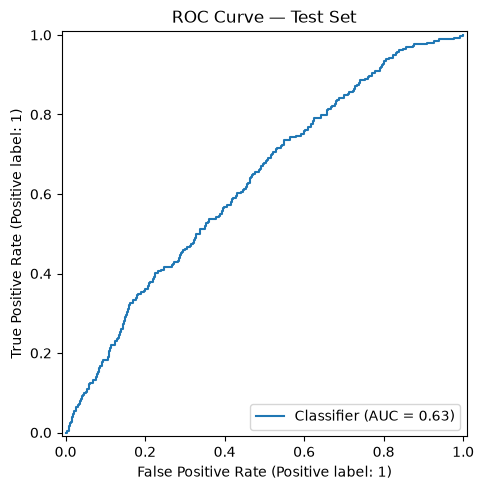

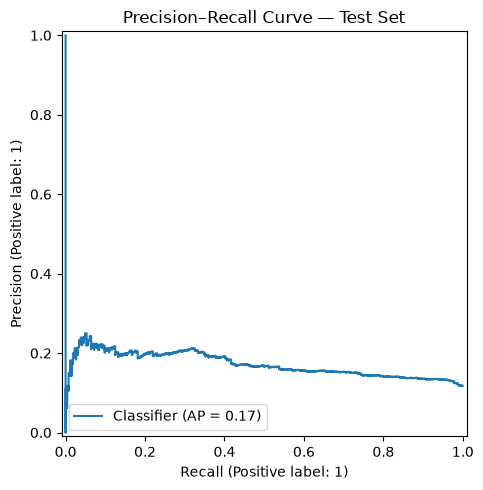

In [20]:
# ROC curve and precision-recall curve on the held-out test set.
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, test_prob, ax=ax)
ax.set_title("ROC Curve — Test Set")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=ax)
ax.set_title("Precision–Recall Curve — Test Set")
plt.tight_layout()
plt.show()

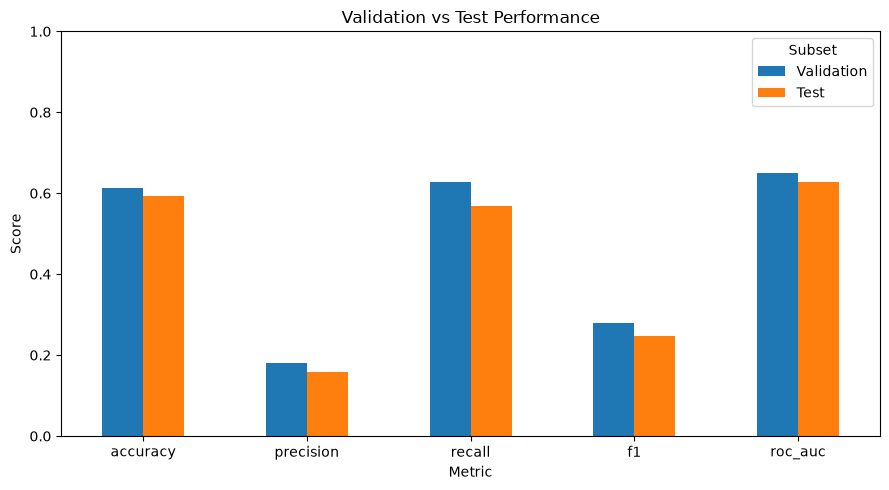

In [21]:
# Compare key metrics on validation and test subsets.
plot_metrics = metrics_table[["accuracy", "precision", "recall", "f1", "roc_auc"]]
ax = plot_metrics.T.plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Validation vs Test Performance")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xlabel("Metric")
plt.legend(title="Subset")
plt.tight_layout()
plt.show()

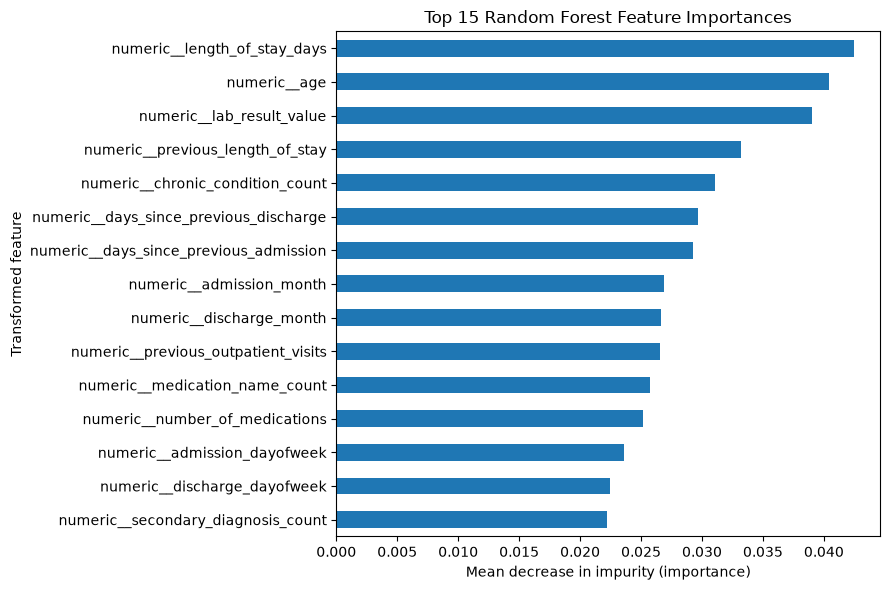

,importance
numeric__length_of_stay_days,0.0425
numeric__age,0.0405
numeric__lab_result_value,0.0390
numeric__previous_length_of_stay,0.0332
numeric__chronic_condition_count,0.0311
numeric__days_since_previous_discharge,0.0297
numeric__days_since_previous_admission,0.0292
numeric__admission_month,0.0268
numeric__discharge_month,0.0266
numeric__previous_outpatient_visits,0.0266


In [22]:
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_rf = model.named_steps["classifier"]
try:
    transformed_names = fitted_preprocessor.get_feature_names_out()
    importances = pd.Series(fitted_rf.feature_importances_, index=transformed_names)
    top_importances = importances.sort_values(ascending=False).head(15).sort_values()
    ax = top_importances.plot(kind="barh", figsize=(9, 6))
    ax.set_title("Top 15 Random Forest Feature Importances")
    ax.set_xlabel("Mean decrease in impurity (importance)")
    ax.set_ylabel("Transformed feature")
    plt.tight_layout()
    plt.show()
    display(top_importances.sort_values(ascending=False).rename("importance").to_frame().round(4))
except Exception as exc:
    print("Feature importance plot could not be created:", exc)